# 04 · DRS and Trajectory Simulation

Fit a ball's path, project it to the stumps with a simple physical model, and show how uncertain the answer is. An educational simulation: it is not Hawk-Eye and not an umpiring tool.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. Why one camera cannot reproduce professional DRS

Professional ball tracking uses six or more synchronised, calibrated, high-speed cameras around the ground. Each camera gives a line of sight to the ball; where the lines cross gives the ball's position in three dimensions to within a few millimetres.

A single phone camera gives one line of sight. A ball that looks 'here' in the image could be anywhere along that line: nearer and lower, or further and higher. Depth is simply not in the picture. On top of that, an uncalibrated camera has unknown lens distortion, the ball is blurred and often hidden near the pad, and a 30 fps video has only two or three frames between bounce and impact.

So this notebook does something more modest and honest:

1. Use the one thing a single camera *can* locate on the pitch: the bounce point, because it lies on the ground.
2. Let a person enter the impact point and height.
3. Project the path with a stated physical model.
4. Vary the inputs inside their uncertainty and report how often the ball hits the stumps.

## 2. Coordinates

- x: metres across from middle stump. Positive = off side.
- y: metres from the striker's stumps toward the bowler (stumps at y = 0).
- z: height above the ground.

The wicket is 22.86 cm wide and 71.1 cm tall; the ball's radius is 3.6 cm.

In [2]:
from pitchvision import trajectory, sample_data
from pitchvision.constants import STUMP_HEIGHT_M, WICKET_HALF_WIDTH_M, BALL_RADIUS_M, GRAVITY, PITCH_LENGTH_M
print(f"Wicket half-width {WICKET_HALF_WIDTH_M:.4f} m, stump height {STUMP_HEIGHT_M} m, ball radius {BALL_RADIUS_M} m")

Wicket half-width 0.1143 m, stump height 0.711 m, ball radius 0.036 m


## 3. From tracked pixels to a bounce point

We start from a tracked path in image pixels (synthetic here; from notebook 03 for a real clip). Before the bounce the ball moves down the image; after it, up. Fitting one straight line to the vertical position on each side of every possible split, and keeping the best split, finds the bounce.

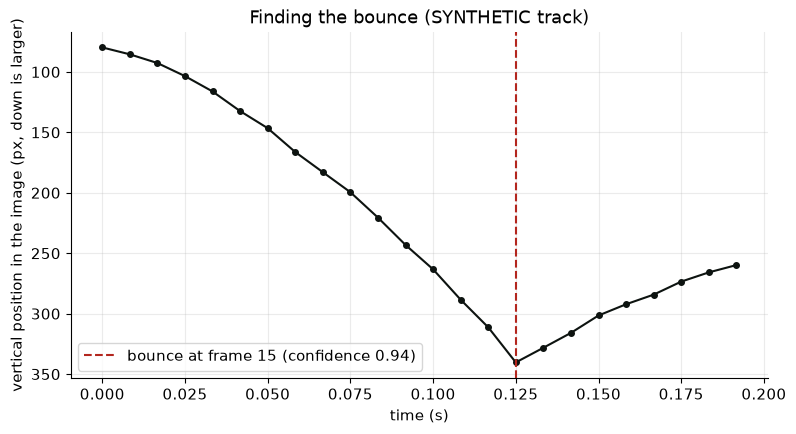

In [3]:
points = sample_data.synthetic_track(seed=4, noise=1.5)      # SYNTHETIC pixel track
bounce = trajectory.detect_bounce(points)
tr = pd.DataFrame(points)
fig, ax = plt.subplots()
ax.plot(tr["t"], tr["y"], "o-", color=INK, ms=4)
ax.axvline(bounce["t"], color=RED, ls="--", label=f"bounce at frame {bounce['frame']} (confidence {bounce['confidence']:.2f})")
ax.invert_yaxis(); ax.set_xlabel("time (s)"); ax.set_ylabel("vertical position in the image (px, down is larger)")
ax.set_title("Finding the bounce (SYNTHETIC track)"); ax.legend(); plt.show()

## 4. Calibration: placing the bounce on the pitch

Four points on the ground with known positions (the ends of the two popping creases) define a homography: a 3×3 matrix that maps any *ground* point in the image to pitch metres. It only works for points on the ground, which is exactly why the bounce can be placed and a ball in the air cannot.

In [4]:
targets = trajectory.standard_calibration_targets()
for t_ in targets: print(t_)

# Pretend the camera maps pitch metres to pixels like this (in real use you click the four points on a frame).
camera = np.array([[60.0, 4.0, 320.0], [1.5, -14.0, 420.0], [0.0, 0.0035, 1.0]])
def to_image(x, y):
    p = camera @ np.array([x, y, 1.0]); return [p[0] / p[2], p[1] / p[2]]

clicked = [to_image(t_["x"], t_["y"]) for t_ in targets]
H = trajectory.fit_homography(clicked, [[t_["x"], t_["y"]] for t_ in targets])
u, v = to_image(0.15, 6.8)                                   # a ball that really bounced at x = 0.15 m, y = 6.8 m
print("Recovered bounce point:", tuple(round(c, 3) for c in trajectory.image_to_pitch(H, u, v)))

# How much does a 3-pixel error in clicking the corners move the answer?
rng = np.random.default_rng(0)
spread = []
for _ in range(300):
    noisy = [[a + rng.normal(0, 3), b + rng.normal(0, 3)] for a, b in clicked]
    spread.append(trajectory.image_to_pitch(trajectory.fit_homography(noisy, [[t_["x"], t_["y"]] for t_ in targets]), u, v))
spread = np.array(spread)
print(f"With 3 px clicking error: x varies by ±{spread[:, 0].std() * 100:.1f} cm, y by ±{spread[:, 1].std() * 100:.1f} cm (1 standard deviation)")

{'label': "Striker's popping crease, off side end", 'x': 1.32, 'y': 1.22}
{'label': "Striker's popping crease, leg side end", 'x': -1.32, 'y': 1.22}
{'label': "Bowler's popping crease, leg side end", 'x': -1.32, 'y': 18.900000000000002}
{'label': "Bowler's popping crease, off side end", 'x': 1.32, 'y': 18.900000000000002}
Recovered bounce point: (0.15, 6.8)
With 3 px clicking error: x varies by ±3.2 cm, y by ±18.5 cm (1 standard deviation)


## 5. The physical model

After the bounce we assume:

- constant speed v along the pitch;
- a straight line sideways (no further swing or spin);
- gravity on height, no air drag.

With the ball pitching at $(x_p, y_p, 0)$ and hitting the pad at $(x_i, y_i, z_i)$:

$$t_1 = \frac{y_p - y_i}{v},\qquad v_{z0} = \frac{z_i + \tfrac12 g t_1^2}{t_1}$$

and at the stumps ($t_2 = y_p / v$):

$$z_{stumps} = v_{z0} t_2 - \tfrac12 g t_2^2,\qquad x_{stumps} = x_p + \frac{x_i - x_p}{y_p - y_i}\, y_p$$

In [5]:
def project_by_hand(pitch_x, pitch_y, impact_x, impact_y, impact_z, speed_kmh):
    v = speed_kmh / 3.6
    t1 = (pitch_y - impact_y) / v
    t2 = pitch_y / v
    vz0 = (impact_z + 0.5 * GRAVITY * t1 ** 2) / t1
    z = vz0 * t2 - 0.5 * GRAVITY * t2 ** 2
    x = pitch_x + (impact_x - pitch_x) / (pitch_y - impact_y) * pitch_y
    return x, z

case = dict(pitch_x=0.10, pitch_y=6.5, impact_x=0.06, impact_y=2.2, impact_z=0.32, speed_kmh=105)
x_hand, z_hand = project_by_hand(**case)
res = trajectory.simulate_drs(**case)
print(f"By hand : x = {x_hand * 100:.1f} cm from middle, z = {z_hand * 100:.1f} cm high")
print(f"Module  : x = {res['projection']['x'] * 100:.1f} cm, z = {res['projection']['z'] * 100:.1f} cm")
assert abs(x_hand - res["projection"]["x"]) < 1e-9 and abs(z_hand - res["projection"]["z"]) < 1e-9

By hand : x = 4.0 cm from middle, z = 40.1 cm high
Module  : x = 4.0 cm, z = 40.1 cm


## 6. Uncertainty

The entered positions are not exact. We redo the projection 4,000 times with each position moved by a random amount (3 cm standard deviation for careful manual entry) and the speed by 10%. The cloud of results shows where the ball could be at the stumps.

Decision rule: at least 80% of the cloud hitting → *hitting*; at most 20% → *missing*; otherwise → *inconclusive*.

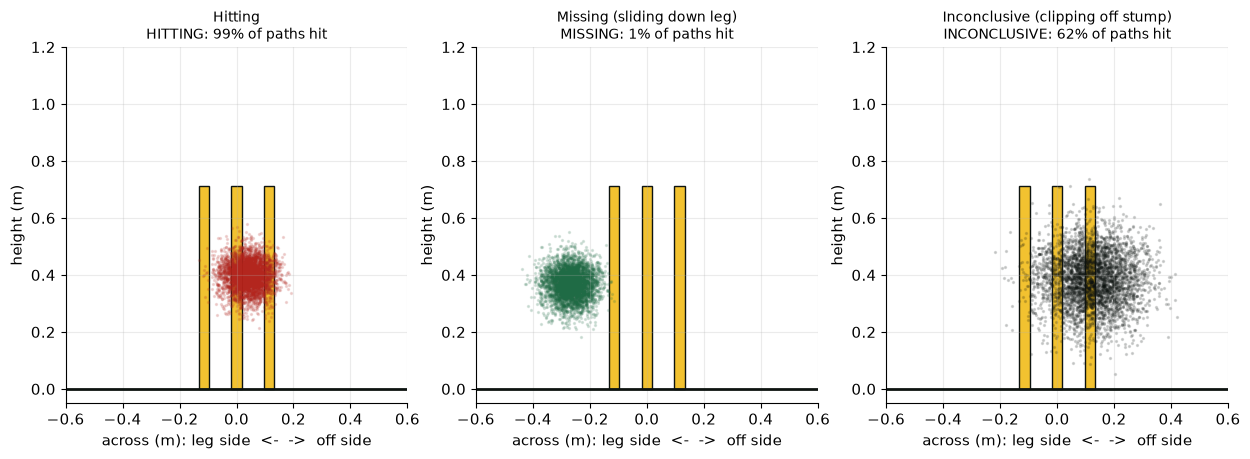

In [6]:
def draw_stumps(ax):
    for s in (-WICKET_HALF_WIDTH_M, 0, WICKET_HALF_WIDTH_M):
        ax.add_patch(plt.Rectangle((s - 0.018, 0), 0.036, STUMP_HEIGHT_M, color=YELLOW, ec=INK))
    ax.axhline(0, color=INK, lw=2)
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.05, 1.2); ax.set_aspect("equal")
    ax.set_xlabel("across (m): leg side  <-  ->  off side"); ax.set_ylabel("height (m)")

def cloud(case, sigma=0.03, speed_sigma=10, n=4000, seed=7):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        c = dict(case)
        for k in ("pitch_x", "pitch_y", "impact_x", "impact_y", "impact_z"):
            c[k] = c[k] + rng.normal(0, sigma)
        c["speed_kmh"] = c["speed_kmh"] * (1 + rng.normal(0, speed_sigma / 100))
        if c["pitch_y"] - c["impact_y"] > 0.05:
            out.append(project_by_hand(**c))
    return np.array(out)

cases = {"Hitting": case,
         "Missing (sliding down leg)": dict(pitch_x=0.05, pitch_y=6.5, impact_x=-0.16, impact_y=2.2, impact_z=0.3, speed_kmh=105),
         "Inconclusive (clipping off stump)": dict(pitch_x=0.0, pitch_y=6.0, impact_x=0.08, impact_y=2.0, impact_z=0.3, speed_kmh=110)}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, c) in zip(axes, cases.items()):
    pts = cloud(c, sigma=0.03 if "Inconclusive" not in title else 0.06)
    r = trajectory.simulate_drs(**c, position_sigma_m=0.03 if "Inconclusive" not in title else 0.06)
    draw_stumps(ax)
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.15, color=RED if r["decision"] == "hitting" else GREEN if r["decision"] == "missing" else INK)
    ax.set_title(f"{title}\n{r['decision'].upper()}: {r['projection']['hit_probability'] * 100:.0f}% of paths hit", fontsize=10)
plt.show()

## 7. Why extrapolation is the weak point

The further the ball still has to travel after hitting the pad, and the shorter the distance it travelled between bounce and pad, the more a small input error grows. Real DRS treats less than 40 cm of post-bounce travel as too little to judge; so does this simulation.

,impact distance from stumps (m),travel after bounce (m),"sideways uncertainty at stumps (cm, 1 sd)","height uncertainty (cm, 1 sd)",decision
0,0.8,5.7,3.5,3.4,hitting
1,1.5,5.0,4.1,4.0,hitting
2,2.5,4.0,5.3,5.2,hitting
3,3.5,3.0,7.5,7.0,hitting
4,4.5,2.0,11.9,10.4,inconclusive
5,5.5,1.0,25.7,21.1,missing


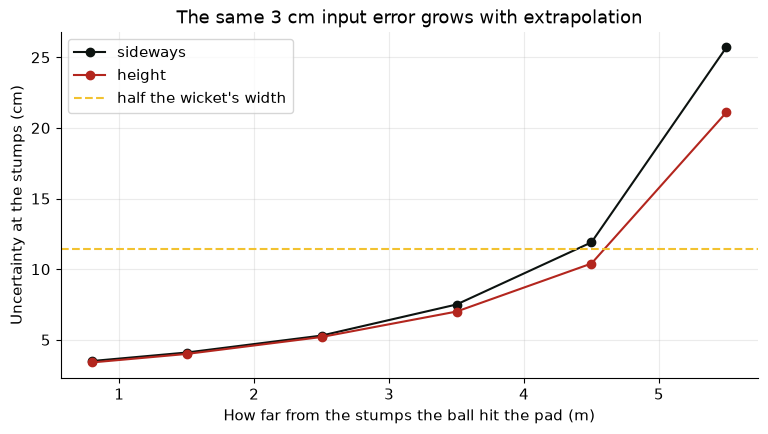

Short travel: inconclusive - Only 30 cm between pitching and impact. Under 40 cm there is too little post-bounce travel to judge the direction.


In [7]:
rows = []
for impact_y in [0.8, 1.5, 2.5, 3.5, 4.5, 5.5]:
    r = trajectory.simulate_drs(0.0, 6.5, 0.0, impact_y, 0.3, speed_kmh=105)
    rows.append({"impact distance from stumps (m)": impact_y, "travel after bounce (m)": round(6.5 - impact_y, 1),
                 "sideways uncertainty at stumps (cm, 1 sd)": round(r["projection"]["x_sigma"] * 100, 1),
                 "height uncertainty (cm, 1 sd)": round(r["projection"]["z_sigma"] * 100, 1), "decision": r["decision"]})
sens = pd.DataFrame(rows); display(sens)

fig, ax = plt.subplots()
ax.plot(sens.iloc[:, 0], sens.iloc[:, 2], marker="o", color=INK, label="sideways")
ax.plot(sens.iloc[:, 0], sens.iloc[:, 3], marker="o", color=RED, label="height")
ax.axhline(WICKET_HALF_WIDTH_M * 100, color=YELLOW, ls="--", label="half the wicket's width")
ax.set_xlabel("How far from the stumps the ball hit the pad (m)"); ax.set_ylabel("Uncertainty at the stumps (cm)")
ax.set_title("The same 3 cm input error grows with extrapolation"); ax.legend(); plt.show()

short = trajectory.simulate_drs(0.0, 2.3, 0.0, 2.0, 0.1)
print("Short travel:", short["decision"], "-", short["reason"])

## 8. Simplified LBW logic (Law 36)

A batter is out LBW only if all of these hold:

1. The ball is not a no-ball.
2. It pitched in line with the stumps or outside off, not outside leg.
3. It did not touch the bat first.
4. It hit the batter in line with the stumps, or outside off if no shot was offered.
5. It would have gone on to hit the stumps.

Simplification: the centre of the ball is used for the pitching and impact tests (real DRS uses more than half the ball).

In [8]:
examples = {
    "Plumb in front": dict(pitch_x=0.0, pitch_y=6.0, impact_x=0.0, impact_y=2.0, impact_z=0.3),
    "Pitched outside leg": dict(pitch_x=-0.30, pitch_y=6.0, impact_x=-0.02, impact_y=2.0, impact_z=0.3),
    "Impact outside off, shot offered": dict(pitch_x=0.5, pitch_y=7.0, impact_x=0.20, impact_y=2.0, impact_z=0.3),
    "Impact outside off, no shot": dict(pitch_x=0.5, pitch_y=7.0, impact_x=0.20, impact_y=2.0, impact_z=0.3, shot_offered=False),
    "No-ball": dict(pitch_x=0.0, pitch_y=6.0, impact_x=0.0, impact_y=2.0, impact_z=0.3, no_ball=True),
    "Too high": dict(pitch_x=0.0, pitch_y=4.0, impact_x=0.0, impact_y=2.5, impact_z=0.75, speed_kmh=120),
    "Missing data": dict(pitch_x=None, pitch_y=None, impact_x=0.0, impact_y=2.0, impact_z=0.3),
}
rows = []
for name, c in examples.items():
    r = trajectory.simulate_drs(**c)
    rows.append({"case": name, "pitched": r.get("pitched", "-"), "impact": r.get("impact", "-"), "wickets": r["decision"],
                 "LBW decision": r.get("lbw", "inconclusive"), "failed conditions": ", ".join(x["name"] for x in r["conditions"] if x["pass"] is False) or "-"})
pd.DataFrame(rows)

,case,pitched,impact,wickets,LBW decision,failed conditions
0,Plumb in front,in line,in line,hitting,out,-
1,Pitched outside leg,outside leg,in line,inconclusive,not_out,Pitching
2,"Impact outside off, shot offered",outside off,outside off,hitting,not_out,Impact
3,"Impact outside off, no shot",outside off,outside off,hitting,out,-
4,No-ball,in line,in line,hitting,not_out,Legal delivery
5,Too high,in line,in line,missing,not_out,Wickets
6,Missing data,-,-,inconclusive,inconclusive,-


In [9]:
# Every result carries its assumptions and limitations.
r = trajectory.simulate_drs(**case)
print("ASSUMPTIONS"); [print(" -", a) for a in r["assumptions"]]
print("LIMITATIONS"); [print(" -", a) for a in r["limitations"]]
pd.DataFrame(rows).to_csv(EXPORTS / "drs_examples.csv", index=False)

ASSUMPTIONS
 - Positions are in metres relative to middle stump (x), the striker's stumps (y) and the ground (z).
 - After the bounce the ball keeps a constant speed along the pitch and a straight line sideways.
 - Height follows gravity only: no air drag, no further swing, no spin effect after impact.
 - Each entered position is uncertain by about 3 cm and the speed by about 10% (one standard deviation).
 - The centre of the ball is used for the pitching and impact tests; the ball's radius is added only when testing contact with the stumps.
 - Single-camera input cannot measure depth, so the impact height and distance are estimates.
LIMITATIONS
 - Not an official DRS and not Hawk-Eye: no multi-camera triangulation, no calibrated high-speed cameras.
 - Camera perspective, lens distortion and motion blur shift where the ball appears to be.
 - The ball is often hidden by the batter or bowler (occlusion) near pitching and impact.
 - Extrapolating from a short post-bounce path magnifies sm

## 9. Before the bounce: a drag-free flight

For completeness, the path from the hand to the pitch for a ball released 2 m high. Faster balls travel flatter; slower balls need more loop to reach the same length.

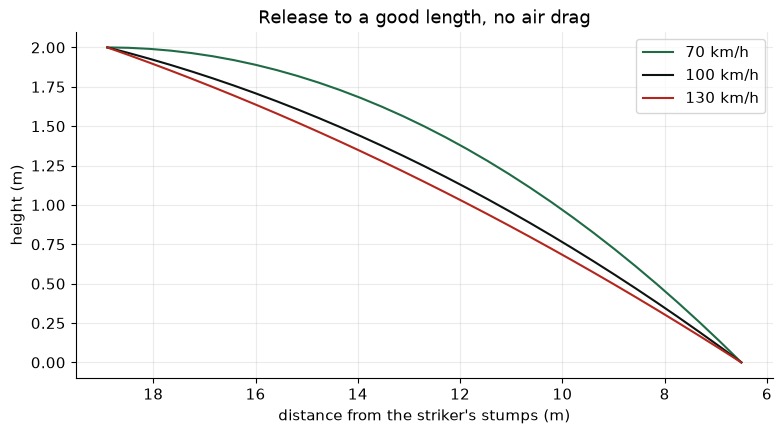

In [10]:
fig, ax = plt.subplots()
for kmh, colour in [(70, GREEN), (100, INK), (130, RED)]:
    p = pd.DataFrame(trajectory.flight_path(2.0, kmh, 6.5))
    ax.plot(p["y"], p["z"], color=colour, label=f"{kmh} km/h")
ax.invert_xaxis(); ax.set_xlabel("distance from the striker's stumps (m)"); ax.set_ylabel("height (m)")
ax.set_title("Release to a good length, no air drag"); ax.legend(); plt.show()

## Summary

### Key findings
- The projection formulas written by hand match `pitchvision.trajectory.simulate_drs` exactly.
- With 3 cm input uncertainty, the uncertainty at the stumps grows from a few centimetres to more than the wicket's half-width as the impact moves away from the stumps.
- The simulation returns hitting, missing or inconclusive, and applies the LBW conditions separately from the ball-tracking result.

### Interpretation
The useful output is not the single projected point but the spread around it. When the spread straddles the edge of the stumps, the honest answer is 'inconclusive'.

### Limitations
- No depth from one camera: impact height and distance are human estimates.
- No air drag, swing after the bounce, or spin are modelled.
- The 80% / 20% decision thresholds are a choice made for teaching, not an official standard.
- The ball's centre is used for the pitching and impact tests.
- This is not an official DRS and must not be used to make or dispute umpiring decisions.

### How this notebook connects to the application
DRS Studio sends the entered points to `POST /api/drs/simulate`, which calls `trajectory.simulate_drs` and draws the same projection, 95% range, decision, LBW conditions, assumptions and limitations. The 'Track from video' tab uses `detect_bounce` and `fit_homography` to supply the pitching point.